# Байесовский классификатор для датасета Iris

Задание:
1. Сформировать обучающую и тестовую выборки: 70% обучающая, 30% тестовая.
2. Показать линии уровня плотности распределения для 3 классов для выбранных признаков.
3. Использовать аппроксимацию нормальным распределением.
4. Показать разделяющие границы байесовского классификатора на плоскости.
5. Использовать собственную реализацию классификатора.
6. Показать ошибки классификации для обучающей и тестовой выборки.

Выбранные признаки: `petal length (cm)` и `petal width (cm)`.
Их можно изменить в переменной `FEATURE_IDX`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split


In [2]:
iris = load_iris()

# Выбранные признаки:
# 2 - petal length (cm)
# 3 - petal width (cm)
FEATURE_IDX = [2, 3]

X = iris.data[:, FEATURE_IDX]
y = iris.target

feature_names = [iris.feature_names[i] for i in FEATURE_IDX]
class_names = list(iris.target_names)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Train shape: (105, 2)
Test shape: (45, 2)


## Собственная реализация байесовского классификатора

Для каждого класса оцениваются параметры нормального распределения:

- априорная вероятность класса: `P(y = c)`;
- среднее: `mu_c`;
- ковариационная матрица: `Sigma_c`.

Классовое правдоподобие:

`p(x | y = c) = N(x | mu_c, Sigma_c)`

Байесовская классификация:

`argmax_c [log P(y = c) + log p(x | y = c)]`


In [3]:
class GaussianBayesClassifier:
    """Байесовский классификатор с нормальными классовыми распределениями."""

    def __init__(self, reg=1e-6):
        self.reg = reg

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        n_samples, n_features = X.shape
        self.classes_ = np.unique(y)
        n_classes = len(self.classes_)

        self.priors_ = np.zeros(n_classes)
        self.means_ = np.zeros((n_classes, n_features))
        self.covs_ = np.zeros((n_classes, n_features, n_features))
        self.inv_covs_ = np.zeros_like(self.covs_)
        self.logdet_covs_ = np.zeros(n_classes)

        for k, c in enumerate(self.classes_):
            Xc = X[y == c]

            self.priors_[k] = Xc.shape[0] / n_samples
            self.means_[k] = Xc.mean(axis=0)

            cov = np.cov(Xc, rowvar=False, bias=False)
            if cov.ndim == 0:
                cov = np.array([[float(cov)]])

            # Регуляризация для устойчивого обращения
            cov = cov + self.reg * np.eye(n_features)

            self.covs_[k] = cov
            self.inv_covs_[k] = np.linalg.inv(cov)
            self.logdet_covs_[k] = np.linalg.slogdet(cov)[1]

        return self

    def class_log_likelihood(self, X):
        X = np.asarray(X, dtype=float)

        n_features = X.shape[1]
        n_classes = len(self.classes_)
        loglik = np.zeros((X.shape[0], n_classes))

        const = n_features * np.log(2.0 * np.pi)

        for k in range(n_classes):
            diff = X - self.means_[k]

            # Mahalanobis distance для каждого объекта
            mahal = np.einsum(
                "ij,jk,ik->i",
                diff,
                self.inv_covs_[k],
                diff
            )

            loglik[:, k] = -0.5 * (
                const + self.logdet_covs_[k] + mahal
            )

        return loglik

    def joint_log_likelihood(self, X):
        return np.log(self.priors_) + self.class_log_likelihood(X)

    def predict_log_proba(self, X):
        jll = self.joint_log_likelihood(X)

        # log-sum-exp для численной устойчивости
        max_jll = jll.max(axis=1, keepdims=True)
        log_sum_exp = max_jll + np.log(
            np.exp(jll - max_jll).sum(axis=1, keepdims=True)
        )

        return jll - log_sum_exp

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))

    def predict(self, X):
        return self.classes_[np.argmax(self.joint_log_likelihood(X), axis=1)]


In [4]:
clf = GaussianBayesClassifier(reg=1e-6).fit(X_train, y_train)

train_pred = clf.predict(X_train)
test_pred = clf.predict(X_test)

train_acc = np.mean(train_pred == y_train)
test_acc = np.mean(test_pred == y_test)

print(f"Train accuracy: {train_acc:.3f}")
print(f"Test accuracy: {test_acc:.3f}")


Train accuracy: 0.981
Test accuracy: 0.933


## Линии уровня плотности распределения классов

Для каждого класса построена плотность нормального распределения,
оценённая по обучающей выборке:

`p(x | y = c) = N(mu_c, Sigma_c)`


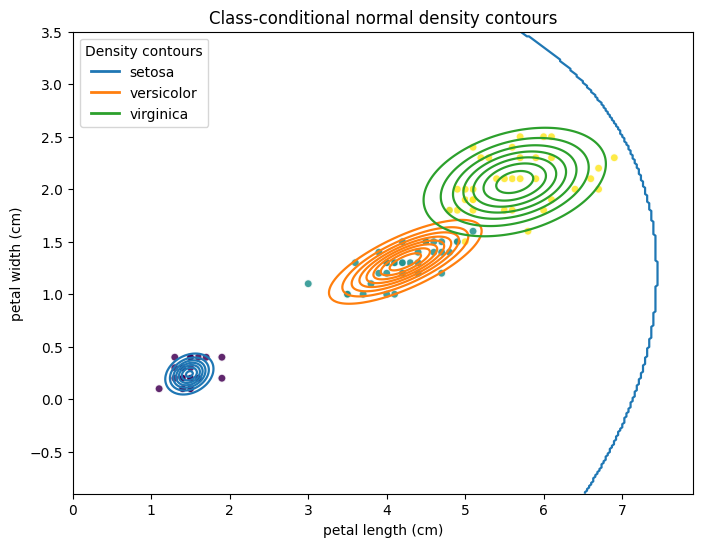

In [5]:
def make_grid(X, padding=1.0, resolution=300):
    x_min, x_max = X[:, 0].min() - padding, X[:, 0].max() + padding
    y_min, y_max = X[:, 1].min() - padding, X[:, 1].max() + padding

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, resolution),
        np.linspace(y_min, y_max, resolution)
    )

    return xx, yy


xx, yy = make_grid(
    np.vstack([X_train, X_test]),
    padding=1.0,
    resolution=300
)

grid = np.c_[xx.ravel(), yy.ravel()]

colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

fig, ax = plt.subplots(figsize=(8, 6))

class_loglik = clf.class_log_likelihood(grid)

for k, c in enumerate(clf.classes_):
    Z = np.exp(class_loglik[:, k]).reshape(xx.shape)

    ax.contour(
        xx, yy, Z,
        levels=8,
        colors=[colors[k]],
        linewidths=1.6
    )

ax.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    cmap="viridis",
    edgecolor="white",
    s=35,
    alpha=0.85
)

handles = [
    Line2D([], [], color=colors[k], lw=2, label=class_names[c])
    for k, c in enumerate(clf.classes_)
]

ax.legend(handles=handles, title="Density contours", loc="upper left")
ax.set_xlabel(feature_names[0])
ax.set_ylabel(feature_names[1])
ax.set_title("Class-conditional normal density contours")

plt.show()


## Разделяющие границы байесовского классификатора

Граница между двумя классами `i` и `j` определяется равенством
лог-апостериорных оценок:

`log P(y = i | x) = log P(y = j | x)`

На графике ниже показаны области решений и линии уровня, соответствующие
разделяющим границам.


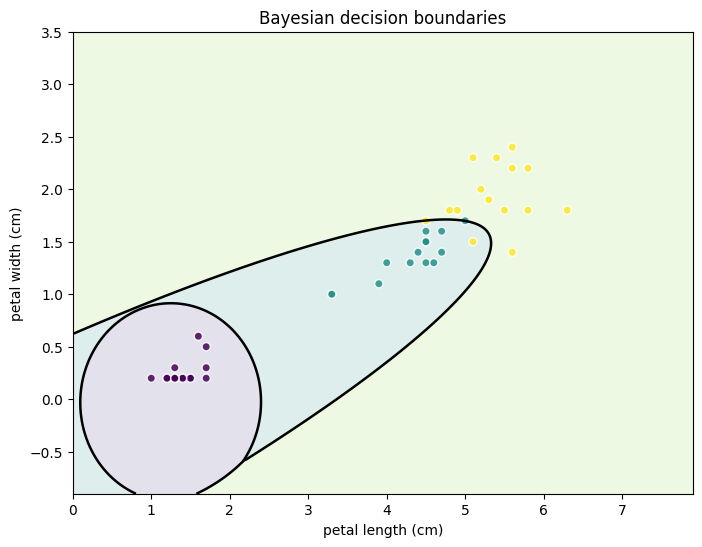

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))

log_post = clf.joint_log_likelihood(grid)
pred_grid = clf.predict(grid).reshape(xx.shape)

# Области решений
ax.contourf(
    xx, yy, pred_grid,
    levels=[-0.5, 0.5, 1.5, 2.5],
    alpha=0.15,
    cmap="viridis"
)

# Разделяющие границы между парами классов
for i, j in [(0, 1), (0, 2), (1, 2)]:
    D = (log_post[:, i] - log_post[:, j]).reshape(xx.shape)

    # Показываем границу только там, где один из двух классов является победителем
    mask = (pred_grid == i) | (pred_grid == j)

    D_masked = np.full(D.shape, np.nan)
    D_masked[mask] = D[mask]

    finite = D_masked[np.isfinite(D_masked)]

    if finite.size > 0 and finite.min() <= 0.0 <= finite.max():
        ax.contour(
            xx, yy, D_masked,
            levels=[0.0],
            colors="black",
            linewidths=1.8
        )

ax.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test,
    cmap="viridis",
    marker="o",
    edgecolor="white",
    s=35,
    alpha=0.85
)

ax.set_xlabel(feature_names[0])
ax.set_ylabel(feature_names[1])
ax.set_title("Bayesian decision boundaries")

plt.show()


## Ошибки классификации

Объекты, на которых классификатор ошибся, выделены красными крестами.


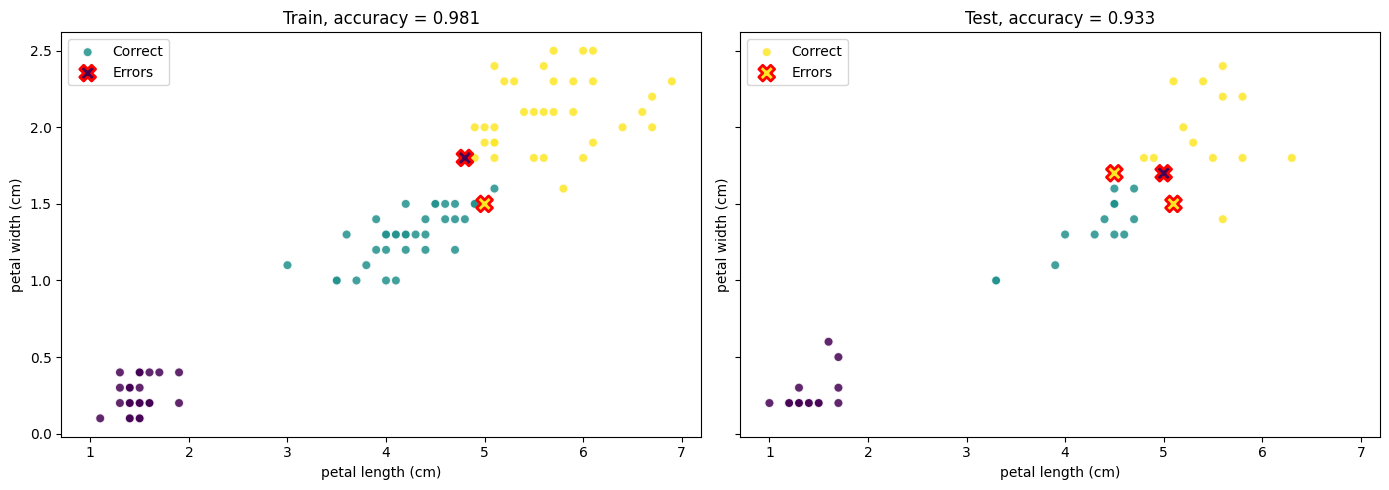

In [7]:
def plot_errors(ax, X, y_true, y_pred, title):
    correct = y_pred == y_true

    ax.scatter(
        X[correct, 0],
        X[correct, 1],
        c=y_true[correct],
        cmap="viridis",
        marker="o",
        edgecolor="white",
        s=45,
        alpha=0.85,
        label="Correct"
    )

    if np.any(~correct):
        ax.scatter(
            X[~correct, 0],
            X[~correct, 1],
            c=y_true[~correct],
            cmap="viridis",
            marker="X",
            edgecolor="red",
            linewidths=2.0,
            s=130,
            label="Errors"
        )

    acc = np.mean(correct)
    ax.set_title(f"{title}, accuracy = {acc:.3f}")
    ax.set_xlabel(feature_names[0])
    ax.set_ylabel(feature_names[1])
    ax.legend(loc="upper left")


fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    sharey=True
)

plot_errors(axes[0], X_train, y_train, train_pred, "Train")
plot_errors(axes[1], X_test, y_test, test_pred, "Test")

plt.tight_layout()
plt.show()
